# OpsMind AI - HDFS Log Anomaly Detection

## Objective
The objective of this notebook is to detect abnormal
HDFS log patterns using labeled event traces.

## Tasks
1. Load HDFS datasets
2. Perform data inspection and analysis
3. Merge event traces with anomaly labels
4. Perform feature engineering
5. Train and evaluate machine learning models
6. Select and save the best model
7. Test anomaly predictions

In [14]:
# Import data handling libraries
import pandas as pd
import numpy as np

# Import file handling library
import os

# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Import machine learning tools
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Import model saving library
import joblib

# Display all columns
pd.set_option("display.max_columns", None)

print("OpsMind AI - HDFS Log Anomaly Detection")
print("Libraries Imported Successfully!")

OpsMind AI - HDFS Log Anomaly Detection
Libraries Imported Successfully!


In [16]:
# Define HDFS dataset folder
hdfs_path = "../data/raw/logs/hdfs/preprocessed"

# Load anomaly labels
labels_df = pd.read_csv(
    os.path.join(hdfs_path, "anomaly_label.csv")
)

# Load event traces
traces_df = pd.read_csv(
    os.path.join(hdfs_path, "Event_traces.csv")
)

# Load log templates - corrected filename
templates_df = pd.read_csv(
    os.path.join(hdfs_path, "HDFS.log_templates.csv")
)

# Display dataset shapes
print("Anomaly Labels Shape:", labels_df.shape)
print("Event Traces Shape:", traces_df.shape)
print("Log Templates Shape:", templates_df.shape)

# Display sample records
display(labels_df.head())
display(traces_df.head())
display(templates_df.head())

Anomaly Labels Shape: (575061, 2)
Event Traces Shape: (575061, 6)
Log Templates Shape: (29, 2)


,BlockId,Label
0,blk_-1608999687919862906,Normal
1,blk_7503483334202473044,Normal
2,blk_-3544583377289625738,Anomaly
3,blk_-9073992586687739851,Normal
4,blk_7854771516489510256,Normal


,BlockId,Label,Type,Features,TimeInterval,Latency
0,blk_-1608999687919862906,Success,NaN,"[E5,E22,E5,E5,E11,E11,E9,E9,E11,E9,E26,E26,E26...","[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",3802
1,blk_7503483334202473044,Success,NaN,"[E5,E5,E22,E5,E11,E9,E11,E9,E11,E9,E26,E26,E26...","[0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",3802
2,blk_-3544583377289625738,Fail,21.0,"[E5,E22,E5,E5,E11,E9,E11,E9,E11,E9,E3,E26,E26,...","[0.0, 1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, ...",3797
3,blk_-9073992586687739851,Success,NaN,"[E5,E22,E5,E5,E11,E9,E11,E9,E11,E9,E26,E26,E26...","[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",50448
4,blk_7854771516489510256,Success,NaN,"[E5,E5,E22,E5,E11,E9,E11,E9,E11,E9,E26,E26,E26...","[0.0, 0.0, 1.0, 48.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",50583


,EventId,EventTemplate
0,E1,[*]Adding an already existing block[*]
1,E2,[*]Verification succeeded for[*]
2,E3,[*]Served block[*]to[*]
3,E4,[*]Got exception while serving[*]to[*]
4,E5,[*]Receiving block[*]src:[*]dest:[*]


In [17]:
# Check duplicate BlockIds before merging
print("Duplicate IDs in Labels:", labels_df["BlockId"].duplicated().sum())
print("Duplicate IDs in Traces:", traces_df["BlockId"].duplicated().sum())

# Remove the existing trace Label column
# We will use anomaly_label.csv as the authoritative target
traces_clean = traces_df.drop(columns=["Label"])

# Merge labels with event traces using BlockId
hdfs_df = pd.merge(
    traces_clean,
    labels_df,
    on="BlockId",
    how="inner",
    validate="one_to_one"
)

# Display merged dataset information
print("Merged HDFS Dataset Shape:", hdfs_df.shape)
print("\nAnomaly Label Distribution:")
print(hdfs_df["Label"].value_counts())

# Display sample records
display(hdfs_df.head())

Duplicate IDs in Labels: 0
Duplicate IDs in Traces: 0
Merged HDFS Dataset Shape: (575061, 6)

Anomaly Label Distribution:
Label
Normal     558223
Anomaly     16838
Name: count, dtype: int64


,BlockId,Type,Features,TimeInterval,Latency,Label
0,blk_-1608999687919862906,NaN,"[E5,E22,E5,E5,E11,E11,E9,E9,E11,E9,E26,E26,E26...","[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",3802,Normal
1,blk_7503483334202473044,NaN,"[E5,E5,E22,E5,E11,E9,E11,E9,E11,E9,E26,E26,E26...","[0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",3802,Normal
2,blk_-3544583377289625738,21.0,"[E5,E22,E5,E5,E11,E9,E11,E9,E11,E9,E3,E26,E26,...","[0.0, 1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, ...",3797,Anomaly
3,blk_-9073992586687739851,NaN,"[E5,E22,E5,E5,E11,E9,E11,E9,E11,E9,E26,E26,E26...","[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",50448,Normal
4,blk_7854771516489510256,NaN,"[E5,E5,E22,E5,E11,E9,E11,E9,E11,E9,E26,E26,E26...","[0.0, 0.0, 1.0, 48.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",50583,Normal


In [18]:
# Check data types
print("Dataset Information:")
print(hdfs_df.dtypes)

# Check missing values
print("\nMissing Values:")
print(hdfs_df.isnull().sum())

# Convert event sequences into text
hdfs_df["event_sequence"] = (
    hdfs_df["Features"]
    .fillna("")
    .astype(str)
    .str.replace(r"[\[\],']", " ", regex=True)
)

# Convert target labels into binary values
# Normal = 0, Anomaly = 1
hdfs_df["target"] = (
    hdfs_df["Label"]
    .map({"Normal": 0, "Anomaly": 1})
)

# Check prepared features
print("\nTarget Distribution:")
print(hdfs_df["target"].value_counts())

display(
    hdfs_df[["BlockId", "event_sequence", "Latency", "target"]].head()
)

Dataset Information:
BlockId             str
Type            float64
Features            str
TimeInterval        str
Latency           int64
Label               str
dtype: object

Missing Values:
BlockId              0
Type            558223
Features             0
TimeInterval         0
Latency              0
Label                0
dtype: int64

Target Distribution:
target
0    558223
1     16838
Name: count, dtype: int64


,BlockId,event_sequence,Latency,target
0,blk_-1608999687919862906,E5 E22 E5 E5 E11 E11 E9 E9 E11 E9 E26 E26 E26...,3802,0
1,blk_7503483334202473044,E5 E5 E22 E5 E11 E9 E11 E9 E11 E9 E26 E26 E26...,3802,0
2,blk_-3544583377289625738,E5 E22 E5 E5 E11 E9 E11 E9 E11 E9 E3 E26 E26 ...,3797,1
3,blk_-9073992586687739851,E5 E22 E5 E5 E11 E9 E11 E9 E11 E9 E26 E26 E26...,50448,0
4,blk_7854771516489510256,E5 E5 E22 E5 E11 E9 E11 E9 E11 E9 E26 E26 E26...,50583,0


In [19]:
# Separate input features and target
X = hdfs_df["event_sequence"]
y = hdfs_df["target"]

# Split data while maintaining class distribution
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("\nTraining Label Distribution:")
print(y_train.value_counts())

print("\nTesting Label Distribution:")
print(y_test.value_counts())

Training Samples: 460048
Testing Samples: 115013

Training Label Distribution:
target
0    446578
1     13470
Name: count, dtype: int64

Testing Label Distribution:
target
0    111645
1      3368
Name: count, dtype: int64


In [20]:
# Initialize TF-IDF vectorizer
tfidf = TfidfVectorizer(
    max_features=5000,
    token_pattern=r"(?u)\b\w+\b"
)

# Fit only on training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing data using the same vocabulary
X_test_tfidf = tfidf.transform(X_test)

# Display feature dimensions
print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)

print("HDFS TF-IDF Feature Extraction Completed!")

Training TF-IDF Shape: (460048, 29)
Testing TF-IDF Shape: (115013, 29)
HDFS TF-IDF Feature Extraction Completed!


In [21]:
# Define four supervised classification models
models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),

    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Multinomial Naive Bayes": MultinomialNB()
}

# Store model results
results = []
trained_models = {}

# Train and evaluate each model
for name, model in models.items():

    print(f"\nTraining {name}...")

    model.fit(X_train_tfidf, y_train)

    predictions = model.predict(X_test_tfidf)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

    trained_models[name] = model

    print(f"{name} Training Completed!")

# Compare all models
hdfs_comparison = pd.DataFrame(results)
hdfs_comparison = hdfs_comparison.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

display(hdfs_comparison)


Training Logistic Regression...
Logistic Regression Training Completed!

Training Linear SVM...
Linear SVM Training Completed!

Training Random Forest...
Random Forest Training Completed!

Training Multinomial Naive Bayes...
Multinomial Naive Bayes Training Completed!


,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.999922,0.997925,0.999406,0.998665
1,Linear SVM,0.998913,0.964480,0.999703,0.981776
2,Logistic Regression,0.998774,0.960342,0.999406,0.979485
3,Multinomial Naive Bayes,0.983402,0.848210,0.527613,0.650558


Best HDFS Model: Random Forest

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00    111645
     Anomaly       1.00      1.00      1.00      3368

    accuracy                           1.00    115013
   macro avg       1.00      1.00      1.00    115013
weighted avg       1.00      1.00      1.00    115013



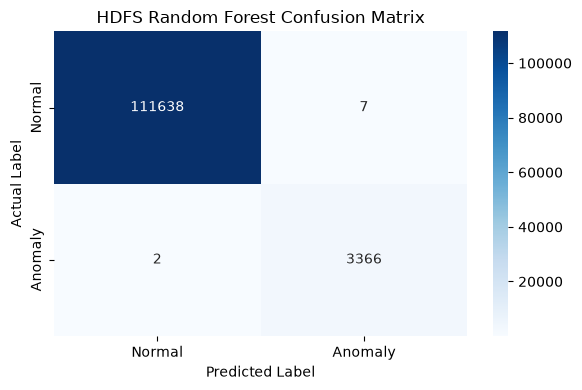

In [22]:
# Select the best performing model
best_model_name = hdfs_comparison.iloc[0]["Model"]
best_model = trained_models[best_model_name]

# Generate predictions
best_predictions = best_model.predict(X_test_tfidf)

# Print best model
print("Best HDFS Model:", best_model_name)

# Display classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    best_predictions,
    target_names=["Normal", "Anomaly"],
    zero_division=0
))

# Generate confusion matrix
cm = confusion_matrix(y_test, best_predictions)

# Plot confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Anomaly"],
    yticklabels=["Normal", "Anomaly"]
)

plt.title("HDFS Random Forest Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [23]:
# Save model and TF-IDF vectorizer together
hdfs_model_package = {
    "model": best_model,
    "vectorizer": tfidf,
    "model_name": best_model_name
}

joblib.dump(
    hdfs_model_package,
    "../data/processed/best_hdfs_anomaly_model.pkl"
)

print("Best HDFS Model Saved Successfully!")

Best HDFS Model Saved Successfully!


In [24]:
# Load the saved HDFS model package
loaded_package = joblib.load(
    "../data/processed/best_hdfs_anomaly_model.pkl"
)

# Extract trained model and vectorizer
loaded_model = loaded_package["model"]
loaded_vectorizer = loaded_package["vectorizer"]

print("Loaded Model:", loaded_package["model_name"])

# Select 10 actual test samples
sample_logs = X_test.iloc[:10]
actual_labels = y_test.iloc[:10]

# Convert samples using saved TF-IDF vectorizer
sample_features = loaded_vectorizer.transform(sample_logs)

# Predict anomaly labels
predictions = loaded_model.predict(sample_features)

# Display actual and predicted results
for log, actual, prediction in zip(
    sample_logs, actual_labels, predictions
):
    actual_name = "ANOMALY" if actual == 1 else "NORMAL"
    predicted_name = "ANOMALY" if prediction == 1 else "NORMAL"

    print("\nEvent Sequence:", log[:150])
    print("Actual Label:", actual_name)
    print("Predicted Label:", predicted_name)
    print("-" * 60)

Loaded Model: Random Forest

Event Sequence:  E22 E5 E5 E5 E26 E11 E9 E26 E26 E11 E9 E11 E9 E4 E4 E4 E4 E4 E4 E4 E4 E4 E4 E4 E4 E4 E4 E3 E4 E2 E23 E23 E23 E21 E21 E21 
Actual Label: NORMAL
Predicted Label: NORMAL
------------------------------------------------------------

Event Sequence:  E5 E5 E22 E5 E11 E9 E11 E9 E11 E9 E26 E26 E26 
Actual Label: NORMAL
Predicted Label: NORMAL
------------------------------------------------------------

Event Sequence:  E5 E5 E22 E5 E11 E9 E11 E9 E11 E9 E26 E26 E26 E2 
Actual Label: NORMAL
Predicted Label: NORMAL
------------------------------------------------------------

Event Sequence:  E5 E5 E5 E22 E11 E9 E11 E9 E26 E26 E11 E9 E26 
Actual Label: NORMAL
Predicted Label: NORMAL
------------------------------------------------------------

Event Sequence:  E22 E5 E5 E5 E11 E9 E11 E9 E26 E11 E9 E26 E26 E23 E23 E23 E21 E21 E21 
Actual Label: NORMAL
Predicted Label: NORMAL
------------------------------------------------------------

Event Sequence

In [25]:
# Calculate final test metrics
print("HDFS ANOMALY DETECTION - FINAL SUMMARY")
print("=" * 50)

print("Dataset Records:", len(hdfs_df))
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("Selected Model:", best_model_name)

print("Accuracy:", round(
    accuracy_score(y_test, best_predictions), 4
))

print("Precision:", round(
    precision_score(y_test, best_predictions), 4
))

print("Recall:", round(
    recall_score(y_test, best_predictions), 4
))

print("F1 Score:", round(
    f1_score(y_test, best_predictions), 4
))

print("\nHDFS Anomaly Detection Completed Successfully!")

HDFS ANOMALY DETECTION - FINAL SUMMARY
Dataset Records: 575061
Training Samples: 460048
Testing Samples: 115013
Selected Model: Random Forest
Accuracy: 0.9999
Precision: 0.9979
Recall: 0.9994
F1 Score: 0.9987

HDFS Anomaly Detection Completed Successfully!
